**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
### get annotated region folder
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

### assign and show
vec_txt_folder = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


## Import data

In [3]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "run_cluster_phenograph"
)
txt_fname = "phenograph.*.coverage.encode_chipseq_full_log2p.cluster.tsv"
txt_fglob = file.path(txt_fdiry, txt_fname)

vec_txt_fpath = Sys.glob(txt_fglob)

lst = lapply(vec_txt_fpath, function(txt_fpath){
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

fun = function(dat1, dat2){full_join(dat1, dat2, by = "Region")}
dat = Reduce(fun, lst)

### assign and show
dat_region_phenograph_cluster = dat
print(any(is.na(dat)))
print(dim(dat))
head(dat)

[1] FALSE
[1] 33953     9


Region,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1:605104-605675,8,10,8,7,7,7,7,7
chr1:778233-779389,6,6,0,0,0,0,0,0
chr1:818708-819335,13,4,8,7,7,5,5,5
chr1:826796-828040,0,6,0,0,0,0,0,0
chr1:842516-843431,1,8,1,1,1,1,1,1
chr1:903783-905204,0,7,3,4,6,6,4,4


In [8]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "run_cluster_phenograph"
)
txt_fname = "phenograph.*.coverage.encode_chipseq_full_log2p.summary.tsv"
txt_fglob = file.path(txt_fdiry, txt_fname)

vec_txt_fpath = Sys.glob(txt_fglob)

lst = lapply(vec_txt_fpath, function(txt_fpath){
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

dat = bind_rows(lst)

### assign and show
dat_region_phenograph_summary = dat
print(any(is.na(dat)))
print(dim(dat))
fun_display_table(dat)

[1] FALSE
[1]  8 11


k,Q,n_clusters,smallest_cluster,largest_cluster,mean_degree,min_degree,max_degree,mean_edge_weight,min_edge_weight,max_edge_weight
30,0.785819,22,57,6091,53.19471,19,1182,0.0816118,0.0084746,0.9354839
40,0.777939,21,55,4525,71.20950,30,1412,0.0861790,0.0063291,0.9047619
50,0.770219,19,57,6792,88.89070,41,1604,0.0902309,0.0050505,0.8867925
60,0.765683,18,88,7089,106.39955,52,1767,0.0937667,0.0042017,0.9047619
70,0.760761,18,52,7210,123.75572,61,1932,0.0969187,0.0035971,0.8918919
80,0.755270,16,55,6885,141.04179,74,2067,0.0997533,0.0031447,0.9512195
90,0.752703,16,103,6986,158.26348,85,2213,0.1022742,0.0027933,0.9354839
100,0.748809,15,197,7303,175.41861,94,2343,0.1045919,0.0025126,0.9417476


In [5]:
library(mclust)

Package 'mclust' version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.


Attaching package: ‘mclust’


The following object is masked from ‘package:purrr’:

    map




In [6]:
adjustedRandIndex(dat_region_phenograph_cluster$Cluster_k30,
                  dat_region_phenograph_cluster$Cluster_k50)

[1] 0.5482042

In [9]:
ks = seq(30, 100, by = 10)
ks

[1]  30  40  50  60  70  80  90 100

In [10]:
ks = seq(30, 100, by = 10)
ks = paste0("Cluster_k", ks)
n <- length(ks)
ari_mat <- matrix(NA, n, n, dimnames = list(ks, ks))

for (i in 1:n) {
  for (j in 1:n) {
    ari_mat[i,j] <- adjustedRandIndex(
      dat_region_phenograph_cluster[[ks[i]]],
      dat_region_phenograph_cluster[[ks[j]]]
    )
  }
}

print(ari_mat)

             Cluster_k30 Cluster_k40 Cluster_k50 Cluster_k60 Cluster_k70
Cluster_k30    1.0000000   0.6681370   0.5482042   0.5330836   0.5340562
Cluster_k40    0.6681370   1.0000000   0.5969078   0.5497077   0.5418759
Cluster_k50    0.5482042   0.5969078   1.0000000   0.8026590   0.7581788
Cluster_k60    0.5330836   0.5497077   0.8026590   1.0000000   0.8513623
Cluster_k70    0.5340562   0.5418759   0.7581788   0.8513623   1.0000000
Cluster_k80    0.5865529   0.6156649   0.7014684   0.7135115   0.7645308
Cluster_k90    0.5125589   0.5363262   0.7840786   0.8344592   0.8781221
Cluster_k100   0.5150496   0.5257199   0.7485627   0.8681315   0.8575245
             Cluster_k80 Cluster_k90 Cluster_k100
Cluster_k30    0.5865529   0.5125589    0.5150496
Cluster_k40    0.6156649   0.5363262    0.5257199
Cluster_k50    0.7014684   0.7840786    0.7485627
Cluster_k60    0.7135115   0.8344592    0.8681315
Cluster_k70    0.7645308   0.8781221    0.8575245
Cluster_k80    1.0000000   0.7763515    0.7


Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths




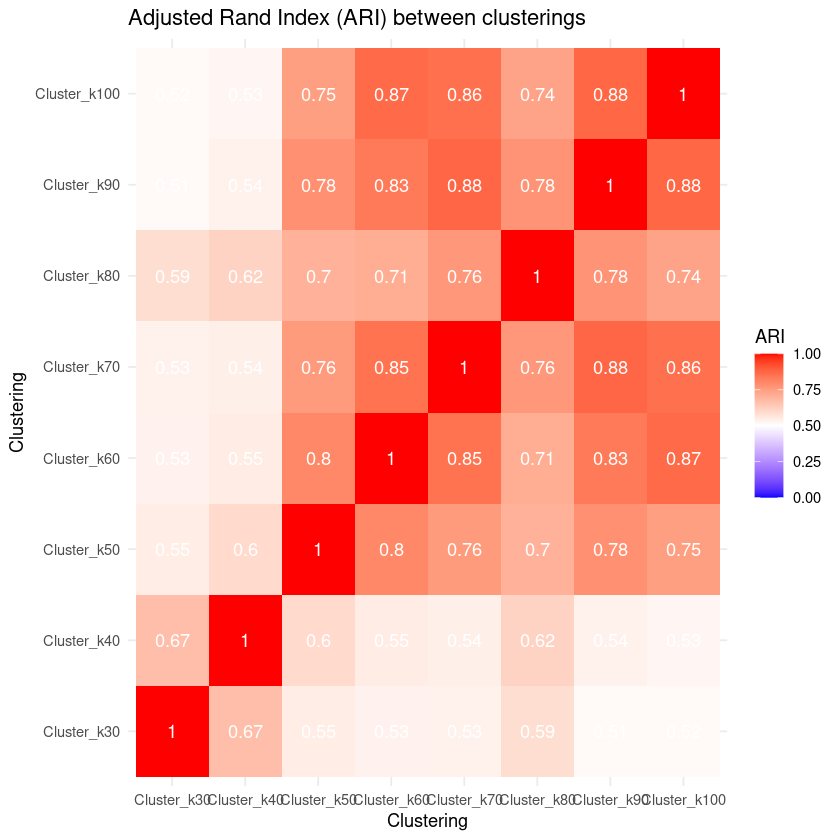

In [11]:
library(ggplot2)
library(reshape2)

df_ari <- melt(ari_mat)
ggplot(df_ari, aes(Var1, Var2, fill = value)) +
  geom_tile() +
  geom_text(aes(label = round(value, 2)), color = "white") +
  scale_fill_gradient2(low = "blue", high = "red", mid = "white",
                       midpoint = 0.5, limit = c(0,1)) +
  theme_minimal() +
  labs(title = "Adjusted Rand Index (ARI) between clusterings",
       x = "Clustering", y = "Clustering", fill = "ARI")

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


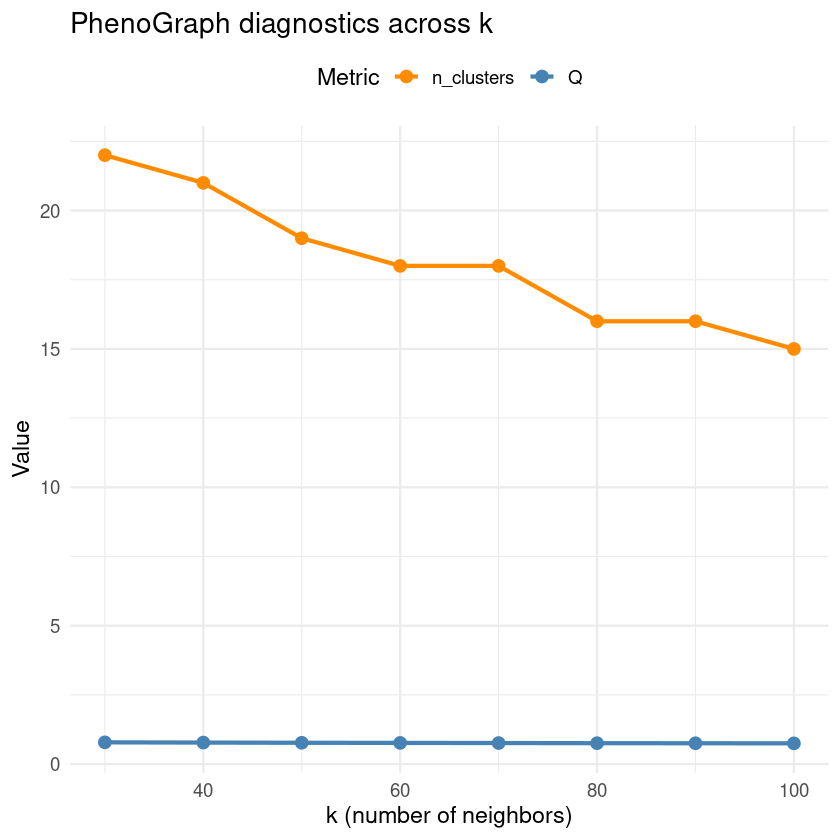

In [12]:
df <- dat_region_phenograph_summary %>%
  select(k, Q, n_clusters) %>%
  pivot_longer(cols = c(Q, n_clusters), names_to = "metric", values_to = "value")

ggplot(df, aes(x = k, y = value, color = metric, group = metric)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  scale_color_manual(values = c("Q" = "steelblue", "n_clusters" = "darkorange")) +
  theme_minimal(base_size = 14) +
  labs(title = "PhenoGraph diagnostics across k",
       x = "k (number of neighbors)",
       y = "Value",
       color = "Metric") +
  theme(legend.position = "top")

## Export results

In [13]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.cluster.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

dat = dat_region_phenograph_cluster
write_tsv(dat, txt_fpath)

In [14]:
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.summary.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

dat = dat_region_phenograph_summary
write_tsv(dat, txt_fpath)